<a href="https://colab.research.google.com/github/tanishgupta1211/college-complaint-classification/blob/main/notebooks/01_project_setup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# College Complaint Classification System

## Project Overview

This project aims to automatically classify college student complaints into relevant categories using Natural Language Processing (NLP) and Machine Learning.

## Objectives
- Collect and analyze a suitable complaint dataset.
- Preprocess English and Hindi/Hinglish complaint text.
- Convert text into numerical features using TF-IDF.
- Train and compare machine learning classification models.
- Evaluate model performance using accuracy, precision, recall, and F1-score.
- Predict the category of a new complaint.

## Tools and Technologies
- Python
- Google Colab
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- GitHub

## Project Workflow
1. Dataset collection
2. Data exploration and cleaning
3. Text preprocessing
4. Feature extraction
5. Model training
6. Model evaluation
7. Complaint prediction

**Project Status:** Day 1 — Project Setup

In [1]:

# Import the libraries we need

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset


In [2]:

# Load the college complaint data

dataset = load_dataset("alaminxpro/university-students-complaints")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))


README.md:   0%|          | 0.00/7.44k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/61.8k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/13.7k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/273 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/59 [00:00<?, ? examples/s]

Training rows: 273
Testing rows: 59


In [3]:

# Count complaints in each category

category_counts = train_df["Category"].value_counts()
print(category_counts)


Category
Infrastructure    114
Technical          58
Academic           48
Finance            29
Administrative     24
Name: count, dtype: int64


In [4]:

# Check for missing and duplicate data

print("Missing values:")
print(train_df.isnull().sum())

print("\nDuplicate rows:", train_df.duplicated().sum())

print(
    "Empty complaints:",
    train_df["Complaint_Description"].fillna("").str.strip().eq("").sum()
)


Missing values:
ID                         0
Timestamp                  0
Gender                     0
Semester                   0
Student_Dept               0
Complaint_Description      0
Category                   0
Responsible_Departments    0
Primary_Department         0
Aspects                    0
Severity                   0
Complaint_Group_ID         0
dtype: int64

Duplicate rows: 0
Empty complaints: 0


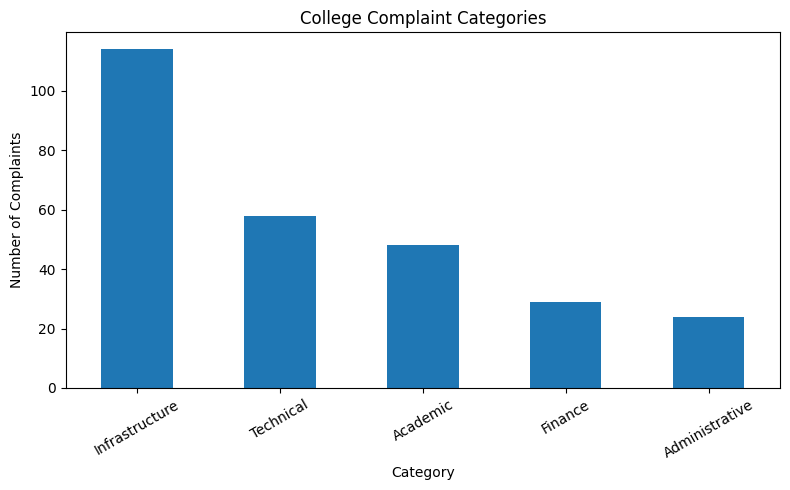

In [5]:

# Plot the complaint categories

category_counts.plot(kind="bar", figsize=(8, 5))

plt.title("College Complaint Categories")
plt.xlabel("Category")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [6]:

print(train_df.shape)
print(test_df.shape)


(273, 12)
(59, 12)


In [7]:
train_df["Complaint_Group_ID"].value_counts().head(10)

,count
Complaint_Group_ID,
20,8
11,4
4,4
8,4
23,4
21,4
19,4
12,4
3,4


In [8]:

train_groups = set(train_df["Complaint_Group_ID"])
test_groups = set(test_df["Complaint_Group_ID"])

common_groups = train_groups.intersection(test_groups)

print("Unique groups in training:", len(train_groups))
print("Unique groups in testing:", len(test_groups))
print("Groups present in both:", len(common_groups))


Unique groups in training: 153
Unique groups in testing: 33
Groups present in both: 0


In [9]:

# Check complaints from group 20

group_data = train_df[train_df["Complaint_Group_ID"] == 20]

display(group_data[["Complaint_Description", "Category"]])


,Complaint_Description,Category
14,We need more research facilities in our univer...,Academic
16,We need more research facilities in our univer...,Academic
64,We would benefit from more research facilities...,Academic
67,We require more research facilities in our uni...,Academic
119,We are in need of more research facilities in ...,Academic
121,We would benefit from more research facilities...,Academic
170,We require more research facilities in our uni...,Academic
171,We are in need of more research facilities in ...,Academic


In [10]:

# Check complaints from group 20

group_data = train_df[train_df["Complaint_Group_ID"] == 20]

display(group_data[["Complaint_Description", "Category"]])


,Complaint_Description,Category
14,We need more research facilities in our univer...,Academic
16,We need more research facilities in our univer...,Academic
64,We would benefit from more research facilities...,Academic
67,We require more research facilities in our uni...,Academic
119,We are in need of more research facilities in ...,Academic
121,We would benefit from more research facilities...,Academic
170,We require more research facilities in our uni...,Academic
171,We are in need of more research facilities in ...,Academic


In [11]:

# Count complaints in each group

group_counts = train_df["Complaint_Group_ID"].value_counts()

print("Total groups:", len(group_counts))
print("Groups with multiple complaints:", (group_counts > 1).sum())
print("Largest group size:", group_counts.max())


Total groups: 153
Groups with multiple complaints: 46
Largest group size: 8


In [12]:

# Check categories within each group

cat_per_group = train_df.groupby("Complaint_Group_ID")["Category"].nunique()

print("Groups with different categories:", (cat_per_group > 1).sum())
print("Groups with one category:", (cat_per_group == 1).sum())


Groups with different categories: 0
Groups with one category: 153


In [13]:

# Check categories in test groups

test_cats = test_df.groupby("Complaint_Group_ID")["Category"].nunique()

print("Test groups with different categories:", (test_cats > 1).sum())
print("Test groups with one category:", (test_cats == 1).sum())


Test groups with different categories: 0
Test groups with one category: 33


## Day 2: Complaint Group Analysis

### Objective
Understand complaint groups and check whether related complaints are separated between training and testing data.

### Work Completed
- Checked complaint counts for each `Complaint_Group_ID`.
- Inspected complaints from Group 20.
- Checked category consistency within training and testing groups.
- Checked for common group IDs between training and testing data.

### Findings
- Training data contains 153 unique groups.
- Testing data contains 33 unique groups.
- 46 training groups contain multiple complaints.
- The largest training group contains 8 complaints.
- All 153 training groups have consistent categories.
- All 33 testing groups have consistent categories.
- No group IDs are shared between training and testing data.

### Conclusion
The group IDs are useful for analysing related complaints. No group overlap was found between the training and testing sets, which reduces the risk of leakage through shared groups.

### Next Step
Prepare complaint text for machine learning and explore text preprocessing techniques.

In [14]:
# Look at a few complaint examples

train_df["Complaint_Description"].head()

,Complaint_Description
0,"On most parts of the 8th/9th floor, WiFi is no..."
1,need a seperate female prayer room which is no...
2,drinking water system on the 6th floor(CSE dpt...
3,Some projectors are not clear
4,Campus WiFi does not work in all areas and is ...


In [15]:
# Check one complaint in its original form

text = train_df["Complaint_Description"].iloc[0]

print("Original complaint:")
print(text)

print("\nLowercase version:")
print(text.lower())

Original complaint:
On most parts of the 8th/9th floor, WiFi is not available at all.

Lowercase version:
on most parts of the 8th/9th floor, wifi is not available at all.


In [16]:
# Convert all complaint text to lowercase

train_df["clean_text"] = train_df["Complaint_Description"].str.lower()

train_df[["Complaint_Description", "clean_text"]].head()

,Complaint_Description,clean_text
0,"On most parts of the 8th/9th floor, WiFi is no...","on most parts of the 8th/9th floor, wifi is no..."
1,need a seperate female prayer room which is no...,need a seperate female prayer room which is no...
2,drinking water system on the 6th floor(CSE dpt...,drinking water system on the 6th floor(cse dpt...
3,Some projectors are not clear,some projectors are not clear
4,Campus WiFi does not work in all areas and is ...,campus wifi does not work in all areas and is ...


In [17]:
# Compare text before and after lowercase conversion

print("Original:")
print(train_df["Complaint_Description"].iloc[0])

print("\nCleaned:")
print(train_df["clean_text"].iloc[0])

print("\nTotal complaints:", len(train_df["clean_text"]))


Original:
On most parts of the 8th/9th floor, WiFi is not available at all.

Cleaned:
on most parts of the 8th/9th floor, wifi is not available at all.

Total complaints: 273


In [18]:
# Compare the length of original and cleaned text

train_df["original_len"] = train_df["Complaint_Description"].str.len()
train_df["clean_len"] = train_df["clean_text"].str.len()

print("Original text length:")
print(train_df["original_len"].describe())

print("\nCleaned text length:")
print(train_df["clean_len"].describe())

Original text length:
count    273.000000
mean     110.699634
std       89.840246
min       24.000000
25%       52.000000
50%       88.000000
75%      133.000000
max      520.000000
Name: original_len, dtype: float64

Cleaned text length:
count    273.000000
mean     110.699634
std       89.840246
min       24.000000
25%       52.000000
50%       88.000000
75%      133.000000
max      520.000000
Name: clean_len, dtype: float64


In [19]:
# Check for missing or blank complaint text

missing = train_df["clean_text"].isna().sum()
blank = train_df["clean_text"].fillna("").str.strip().eq("").sum()

print("Missing complaints:", missing)
print("Blank complaints:", blank)

Missing complaints: 0
Blank complaints: 0


In [20]:
# Import TF-IDF for converting text into numbers

from sklearn.feature_extraction.text import TfidfVectorizer

In [21]:
# Create the TF-IDF vectorizer

tfidf = TfidfVectorizer(max_features=1000)

print(tfidf)

TfidfVectorizer(max_features=1000)


In [22]:
# Convert training complaints into numerical features

x_train = tfidf.fit_transform(train_df["clean_text"])

print("Shape:", x_train.shape)
print("Data type:", type(x_train))

Shape: (273, 645)
Data type: <class 'scipy.sparse._csr.csr_matrix'>


In [23]:
# View the words and their TF-IDF values

words = tfidf.get_feature_names_out()
values = x_train[0].toarray()[0]

word_data = pd.DataFrame({
    "word": words,
    "tfidf": values
})

word_data = word_data[word_data["tfidf"] > 0]
word_data = word_data.sort_values("tfidf", ascending=False)

display(word_data.head(10))

,word,tfidf
8,9th,0.356759
58,available,0.356759
404,parts,0.356759
7,8th,0.309448
355,most,0.301409
25,all,0.301409
634,wifi,0.257999
229,floor,0.250407
381,on,0.243576
52,at,0.234462


In [24]:
# Convert test complaints using the same TF-IDF vocabulary

test_df["clean_text"] = test_df["Complaint_Description"].str.lower()

x_test = tfidf.transform(test_df["clean_text"])

y_train = train_df["Category"]
y_test = test_df["Category"]

print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (273, 645)
Testing features: (59, 645)
Training labels: (273,)
Testing labels: (59,)


In [25]:
# Import the classification model

from sklearn.linear_model import LogisticRegression

In [26]:
# Create and train the model

model = LogisticRegression(max_iter=1000)

model.fit(x_train, y_train)

print("Model training complete!")

Model training complete!


In [27]:
# Predict categories for unseen complaints

y_pred = model.predict(x_test)

print("Actual categories:")
print(y_test.head(10).to_list())

print("\nPredicted categories:")
print(y_pred[:10])

Actual categories:
['Infrastructure', 'Technical', 'Academic', 'Infrastructure', 'Infrastructure', 'Administrative', 'Technical', 'Infrastructure', 'Infrastructure', 'Academic']

Predicted categories:
['Infrastructure' 'Infrastructure' 'Infrastructure' 'Infrastructure'
 'Infrastructure' 'Infrastructure' 'Infrastructure' 'Infrastructure'
 'Infrastructure' 'Infrastructure']


In [28]:
# Check how many test predictions are correct

from sklearn.metrics import accuracy_score

acc = accuracy_score(y_test, y_pred)

print("Test accuracy:", round(acc * 100, 2), "%")

Test accuracy: 55.93 %


In [29]:
# Evaluate performance for each complaint category

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, zero_division=0))

                precision    recall  f1-score   support

      Academic       1.00      0.06      0.12        16
Administrative       0.00      0.00      0.00         3
       Finance       1.00      0.50      0.67         4
Infrastructure       0.56      1.00      0.72        29
     Technical       0.25      0.14      0.18         7

      accuracy                           0.56        59
     macro avg       0.56      0.34      0.34        59
  weighted avg       0.64      0.56      0.45        59



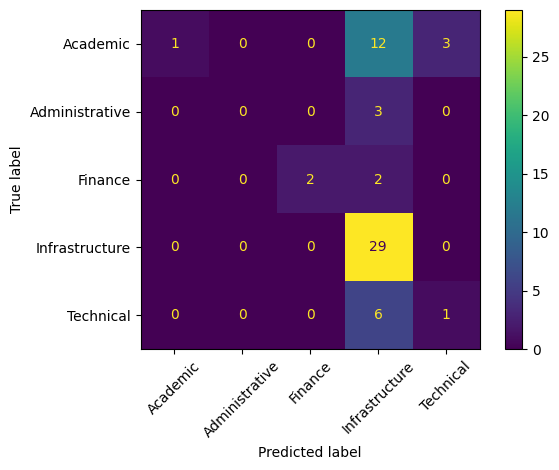

In [30]:
# See which categories the model confuses

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(xticks_rotation=45)
plt.tight_layout()
plt.show()

In [31]:
# Train a model that gives more weight to smaller classes

balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

balanced_model.fit(x_train, y_train)

balanced_pred = balanced_model.predict(x_test)

print(classification_report(
    y_test,
    balanced_pred,
    zero_division=0
))

                precision    recall  f1-score   support

      Academic       1.00      0.56      0.72        16
Administrative       0.75      1.00      0.86         3
       Finance       0.50      1.00      0.67         4
Infrastructure       0.87      0.93      0.90        29
     Technical       0.43      0.43      0.43         7

      accuracy                           0.78        59
     macro avg       0.71      0.78      0.71        59
  weighted avg       0.82      0.78      0.78        59



In [32]:
# Compare both models on the same test data

from sklearn.metrics import accuracy_score, f1_score

print("Baseline accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Balanced accuracy:",
      round(accuracy_score(y_test, balanced_pred), 4))

print("Baseline macro F1:",
      round(f1_score(y_test, y_pred, average="macro"), 4))

print("Balanced macro F1:",
      round(f1_score(y_test, balanced_pred, average="macro"), 4))

Baseline accuracy: 0.5593
Balanced accuracy: 0.7797
Baseline macro F1: 0.3364
Balanced macro F1: 0.7145


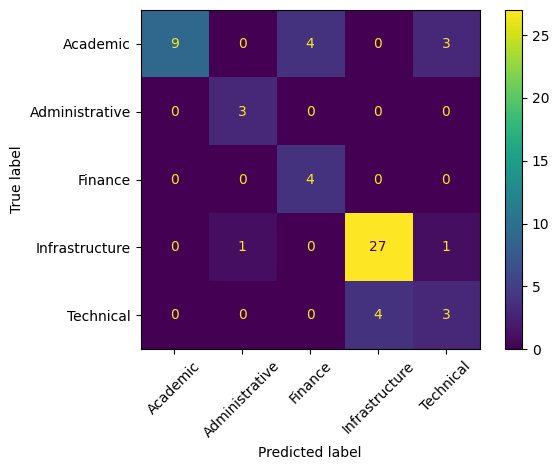

In [33]:
# Check errors made by the balanced model

cm_bal = confusion_matrix(
    y_test,
    balanced_pred,
    labels=balanced_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_bal,
    display_labels=balanced_model.classes_
)

disp.plot(xticks_rotation=45)
plt.tight_layout()
plt.show()

## Day 3: Text Preprocessing

### Objective
Understand the complaint text and prepare it for machine learning.

### Work Completed
- Inspected sample complaints from the training dataset.
- Converted complaint text to lowercase.
- Created a new `clean_text` column while preserving the original complaint descriptions.
- Compared original and cleaned text lengths.
- Checked for missing and blank complaint descriptions.

### Code Summary
```python
train_df["clean_text"] = train_df["Complaint_Description"].str.lower()
```

### Findings
- The training dataset contains 273 complaints.
- Average complaint length is approximately 111 characters.
- Median complaint length is 88 characters.
- The shortest complaint contains 24 characters.
- The longest complaint contains 520 characters.
- No missing or blank complaints were found in the training text.
- Lowercase conversion did not change the length of the complaints.

### Key Learnings
- Text preprocessing helps maintain consistency in complaint text.
- The original text should be preserved for comparison and analysis.
- Aggressive cleaning is not always necessary because punctuation and numbers may provide useful context.
- Common words will be handled through TF-IDF rather than being removed blindly.

### Conclusion
Basic text preprocessing was completed successfully. The training complaints are ready for TF-IDF feature extraction.

### Next Step
Convert complaint text into numerical features using TF-IDF.


## Day 4: TF-IDF and Initial Model Training

### Objective
Convert complaint text into numerical features, train a classification model, and evaluate its performance.

### Work Completed
- Imported `TfidfVectorizer` from scikit-learn.
- Created a TF-IDF vectorizer with a maximum of 1,000 features.
- Converted training complaints into numerical features.
- Converted test complaints using the same fitted vectorizer.
- Separated text features (`X`) and category labels (`y`).
- Trained a Logistic Regression baseline model.
- Evaluated predictions using accuracy, classification report, and confusion matrix.
- Trained a second model using balanced class weights.
- Compared the performance of both models.

### TF-IDF Feature Extraction
```python
tfidf = TfidfVectorizer(max_features=1000)

x_train = tfidf.fit_transform(train_df["clean_text"])
x_test = tfidf.transform(test_df["clean_text"])
```

The vectorizer generated 645 features from the training text. TF-IDF assigns numerical weights to words based on their importance within a document and the overall training corpus.

The test data was transformed using the training vocabulary to avoid information leakage.

### Models Trained
1. **Baseline model:** Logistic Regression with default class weighting.
2. **Balanced model:** Logistic Regression using `class_weight="balanced"`.

### Evaluation Results

| Metric | Baseline | Balanced |
|---|---:|---:|
| Test accuracy | 55.93% | 77.97% |
| Macro F1-score | 0.3364 | 0.7145 |

### Key Findings
- The baseline model tended to predict Infrastructure for many complaints.
- The balanced model improved recognition of less represented categories.
- Academic and Technical complaints remain challenging.
- Administrative and Finance results were strong, but their test samples were small.
- The balanced model performed better on this test set and is the stronger candidate so far.

### Limitations
- The dataset contains a relatively small number of labeled complaints.
- The test set contains only 59 complaints.
- Performance on English complaints does not establish performance on Hindi or Hinglish complaints.
- Further validation is required before selecting the final model.

### Conclusion
TF-IDF and Logistic Regression successfully established a baseline classification system. Applying balanced class weights improved test accuracy and macro F1-score.

### Next Step
Compare model settings using training data and validation, analyse remaining classification errors, and carefully evaluate the selected model.


In [34]:
# Split training data into training and validation sets

from sklearn.model_selection import train_test_split

x_tr, x_val, y_tr, y_val = train_test_split(
    train_df["clean_text"],
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(x_tr))
print("Validation samples:", len(x_val))

Training samples: 218
Validation samples: 55


In [35]:
# Create TF-IDF features using training data only

tfidf_val = TfidfVectorizer(max_features=1000)

x_tr_vec = tfidf_val.fit_transform(x_tr)
x_val_vec = tfidf_val.transform(x_val)

print("Training features:", x_tr_vec.shape)
print("Validation features:", x_val_vec.shape)

Training features: (218, 606)
Validation features: (55, 606)


In [36]:
# Train baseline and balanced models on the same split

base_model = LogisticRegression(max_iter=1000)
base_model.fit(x_tr_vec, y_tr)

bal_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)
bal_model.fit(x_tr_vec, y_tr)

# Predict validation categories

base_pred = base_model.predict(x_val_vec)
bal_pred = bal_model.predict(x_val_vec)

print("Both models trained and predictions completed!")

Both models trained and predictions completed!


In [37]:
# Compare models on validation data

from sklearn.metrics import accuracy_score, f1_score

print("Baseline accuracy:",
      round(accuracy_score(y_val, base_pred) * 100, 2), "%")

print("Balanced accuracy:",
      round(accuracy_score(y_val, bal_pred) * 100, 2), "%")

print("Baseline macro F1:",
      round(f1_score(y_val, base_pred, average="macro", zero_division=0), 4))

print("Balanced macro F1:",
      round(f1_score(y_val, bal_pred, average="macro", zero_division=0), 4))

Baseline accuracy: 87.27 %
Balanced accuracy: 94.55 %
Baseline macro F1: 0.8297
Balanced macro F1: 0.9474


In [38]:
# Evaluate the balanced model on validation data

print(classification_report(
    y_val,
    bal_pred,
    zero_division=0
))

                precision    recall  f1-score   support

      Academic       1.00      1.00      1.00         9
Administrative       1.00      0.80      0.89         5
       Finance       1.00      1.00      1.00         6
Infrastructure       0.88      1.00      0.94        23
     Technical       1.00      0.83      0.91        12

      accuracy                           0.95        55
     macro avg       0.98      0.93      0.95        55
  weighted avg       0.95      0.95      0.94        55



## Day 5: Model Validation and Comparison

### Objective
Validate model performance on a separate validation split and compare baseline and balanced Logistic Regression models.

### Work Completed
- Split the 273 training complaints into 218 training and 55 validation samples.
- Used stratified splitting to maintain category proportions as closely as possible.
- Fitted a new TF-IDF vectorizer only on the training portion.
- Transformed validation text using the same fitted vectorizer.
- Trained baseline and balanced Logistic Regression models.
- Compared accuracy, macro F1-score, and category-wise classification metrics.

### Validation Results

| Metric | Baseline | Balanced |
|---|---:|---:|
| Accuracy | 87.27% | 94.55% |
| Macro F1-score | 0.8297 | 0.9474 |

### Balanced Model: Category-wise Findings
- Academic: F1-score 1.00, support 9.
- Administrative: F1-score 0.89, support 5.
- Finance: F1-score 1.00, support 6.
- Infrastructure: F1-score 0.94, support 23.
- Technical: F1-score 0.91, support 12.

### Conclusion
The balanced Logistic Regression model performed better than the baseline on this validation split. Its validation accuracy was 94.55%, with a macro F1-score of 0.9474.

### Limitations
- The validation set contains only 55 complaints, so results may vary across different splits.
- Validation performance is not a guarantee of future performance.
- The original test set must remain separate from model tuning.
- Hindi and Hinglish complaint performance has not yet been evaluated.

### Next Steps
Continue controlled experiments using training and validation data, document the results, and reserve the test set for final evaluation.


In [39]:
# Try TF-IDF with single words and word pairs

tfidf_ng = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2)
)

x_tr_ng = tfidf_ng.fit_transform(x_tr)
x_val_ng = tfidf_ng.transform(x_val)

print("Training features:", x_tr_ng.shape)
print("Validation features:", x_val_ng.shape)

Training features: (218, 1000)
Validation features: (55, 1000)


In [40]:
# Train a balanced model using words and word pairs

ng_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

ng_model.fit(x_tr_ng, y_tr)

ng_pred = ng_model.predict(x_val_ng)

print("N-gram model trained!")

N-gram model trained!


In [41]:
# Compare the original and n-gram models

print("Previous balanced accuracy:",
      round(accuracy_score(y_val, bal_pred) * 100, 2), "%")

print("N-gram accuracy:",
      round(accuracy_score(y_val, ng_pred) * 100, 2), "%")

print("Previous balanced macro F1:",
      round(f1_score(y_val, bal_pred, average="macro", zero_division=0), 4))

print("N-gram macro F1:",
      round(f1_score(y_val, ng_pred, average="macro", zero_division=0), 4))

Previous balanced accuracy: 94.55 %
N-gram accuracy: 96.36 %
Previous balanced macro F1: 0.9474
N-gram macro F1: 0.9607


In [42]:
# Evaluate each category for the n-gram model

print(classification_report(
    y_val,
    ng_pred,
    zero_division=0
))

                precision    recall  f1-score   support

      Academic       1.00      1.00      1.00         9
Administrative       1.00      0.80      0.89         5
       Finance       1.00      1.00      1.00         6
Infrastructure       0.92      1.00      0.96        23
     Technical       1.00      0.92      0.96        12

      accuracy                           0.96        55
     macro avg       0.98      0.94      0.96        55
  weighted avg       0.97      0.96      0.96        55



## Day 6: TF-IDF N-gram Experiment

### Objective
Test whether adding two-word phrases to TF-IDF improves complaint classification.

### Experiment
- Used the same training and validation split as Day 5.
- Configured TF-IDF with `max_features=1000` and `ngram_range=(1, 2)`.
- Trained a balanced Logistic Regression model using the new features.
- Compared the model with the previous balanced model using validation accuracy and macro F1-score.

### Results

| Metric | Previous Balanced Model | Balanced N-gram Model |
|---|---:|---:|
| Validation accuracy | 94.55% | 96.36% |
| Validation macro F1 | 0.9474 | 0.9607 |

### Category-wise Findings
- Academic: F1-score 1.00, support 9.
- Administrative: F1-score 0.89, support 5.
- Finance: F1-score 1.00, support 6.
- Infrastructure: F1-score 0.96, support 23.
- Technical: F1-score 0.96, support 12.

### Conclusion
Adding unigrams and bigrams improved validation performance on this split. The balanced n-gram model is the strongest candidate so far.

### Limitations
- The validation set contains only 55 complaints.
- High validation scores do not guarantee similar performance on new complaints.
- Hindi and Hinglish complaint performance has not been evaluated.
- The test set remains reserved for final evaluation.

### Next Step
Document the experiment, review remaining classification errors, and continue controlled model selection using training and validation data.


In [43]:
# Find validation complaints predicted incorrectly

val_results = pd.DataFrame({
    "complaint": x_val.reset_index(drop=True),
    "actual": y_val.reset_index(drop=True),
    "predicted": ng_pred
})

wrong = val_results[val_results["actual"] != val_results["predicted"]]

print("Total validation complaints:", len(val_results))
print("Incorrect predictions:", len(wrong))

display(wrong)

Total validation complaints: 55
Incorrect predictions: 2


,complaint,actual,predicted
24,most of the computers at the labs have problem...,Technical,Infrastructure
29,each floor should have one wheelchair in servi...,Administrative,Infrastructure


In [44]:
# Display the complete text of incorrect predictions

for _, row in wrong.iterrows():
    print("Complaint:", row["complaint"])
    print("Actual:", row["actual"])
    print("Predicted:", row["predicted"])
    print("-" * 60)

Complaint: most of the computers at the labs have problems; they should be fixed. kindly verify and take action.
Actual: Technical
Predicted: Infrastructure
------------------------------------------------------------
Complaint: each floor should have one wheelchair in service. please look into it.
Actual: Administrative
Predicted: Infrastructure
------------------------------------------------------------


## Day 7: Error Analysis and Model Selection

### Objective
Inspect incorrect validation predictions and understand the limitations of the current best model.

### Model Evaluated
Balanced Logistic Regression with TF-IDF unigrams and bigrams.

### Validation Results
- Total validation complaints: 55
- Correct predictions: 53
- Incorrect predictions: 2
- Accuracy: 96.36%
- Macro F1-score: 0.9607

### Errors Analysed

**1. Computer laboratory problems**
- Actual category: Technical
- Predicted category: Infrastructure
- Possible explanation: The words "computers" and "labs" may associate the complaint with physical facilities, although the primary issue is computer malfunction.

**2. Wheelchair availability**
- Actual category: Administrative
- Predicted category: Infrastructure
- Possible explanation: References to floors and wheelchair availability may resemble facility-related complaints. The dataset labels this complaint as Administrative.

### Key Learnings
- A model may rely on correlated words instead of correctly distinguishing the main issue.
- Related categories can contain overlapping vocabulary.
- Error analysis helps identify where the model may need better examples or improved features.
- High validation performance on a small dataset does not guarantee the same performance on unseen real-world complaints.

### Conclusion
The balanced n-gram model is the strongest candidate so far based on validation accuracy and macro F1-score. Two validation errors were identified and inspected.

### Next Step
Document model selection, preserve the test set for final evaluation, and plan further validation and testing with additional complaint examples, including Hindi and Hinglish.


In [45]:
# Retrain the selected model on all training data

final_tfidf = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2)
)

x_train_final = final_tfidf.fit_transform(train_df["clean_text"])

final_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

final_model.fit(x_train_final, train_df["Category"])

print("Final model training complete!")
print("Training feature shape:", x_train_final.shape)

Final model training complete!
Training feature shape: (273, 1000)


In [46]:
# Evaluate the final model on the untouched test set

x_test_final = final_tfidf.transform(test_df["Complaint_Description"].str.lower())
y_test_final = test_df["Category"]

final_pred = final_model.predict(x_test_final)

print("Test accuracy:",
      round(accuracy_score(y_test_final, final_pred) * 100, 2), "%")

print("\nClassification report:")
print(classification_report(
    y_test_final,
    final_pred,
    zero_division=0
))

Test accuracy: 67.8 %

Classification report:
                precision    recall  f1-score   support

      Academic       1.00      0.38      0.55        16
Administrative       0.00      0.00      0.00         3
       Finance       0.75      0.75      0.75         4
Infrastructure       0.79      0.93      0.86        29
     Technical       0.50      0.57      0.53         7

      accuracy                           0.68        59
     macro avg       0.61      0.53      0.54        59
  weighted avg       0.77      0.68      0.68        59



In [47]:
# Save the trained model and TF-IDF vectorizer

import os
import joblib

os.makedirs("models", exist_ok=True)

joblib.dump(final_model, "models/complaint_model.joblib")
joblib.dump(final_tfidf, "models/tfidf_vectorizer.joblib")

print("Model and vectorizer saved!")

Model and vectorizer saved!


In [48]:
# Connect Google Drive

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [49]:
# Save model files permanently in Google Drive

import os
import shutil

save_dir = "/content/drive/MyDrive/college_complaint_models"

os.makedirs(save_dir, exist_ok=True)

shutil.copy2(
    "models/complaint_model.joblib",
    save_dir
)

shutil.copy2(
    "models/tfidf_vectorizer.joblib",
    save_dir
)

print("Model files saved to Google Drive!")

print("\nFiles saved:")
print(os.listdir(save_dir))

Model files saved to Google Drive!

Files saved:
['complaint_model.joblib', 'tfidf_vectorizer.joblib']


In [50]:
# Test the model on a new complaint

complaint = [
    "The WiFi is not working in the college library."
]

complaint_vec = final_tfidf.transform(complaint)

prediction = final_model.predict(complaint_vec)

print("Complaint:", complaint[0])
print("Predicted category:", prediction[0])

Complaint: The WiFi is not working in the college library.
Predicted category: Technical


## Day 8: Final Model Evaluation and Saving

### Objective
Evaluate the selected model on the original test set, save the model artifacts, and test a new complaint.

### Final Model
- TF-IDF Vectorizer with `max_features=1000`
- `ngram_range=(1, 2)` to include unigrams and bigrams
- Logistic Regression with `class_weight="balanced"`

### Final Test Results
- Test samples: 59
- Test accuracy: 67.80%
- Macro F1-score: 0.54

### Key Findings
- Infrastructure was the strongest category by F1-score (0.86).
- Administrative complaints were not correctly identified in the test set.
- The final test performance was lower than the validation performance, indicating that generalization remains a challenge.
- More labeled examples and further evaluation are needed, especially for underrepresented categories.

### Model Storage
Saved the following files in Google Drive under `college_complaint_models`:
- `complaint_model.joblib`
- `tfidf_vectorizer.joblib`

### New Complaint Experiment
- Complaint: "The WiFi is not working in the college library."
- Predicted category: Technical
- Note: The correct category depends on the dataset's labeling guidelines; the prediction requires verification against those guidelines or a manually labeled example.

### Limitations
- The dataset is relatively small.
- Hindi and Hinglish performance has not been evaluated.
- The final test results should be reported honestly and not replaced by validation scores.

### Next Step
Review category definitions, test additional manually labeled examples, and document the project limitations and future improvements.


In [51]:
# Test the model on different complaint types

complaints = [
    "The WiFi is not working in the college library.",
    "The computers in the lab keep crashing.",
    "My tuition fee payment has not been updated.",
    "The professor has not uploaded the assignment marks.",
    "The college office has not issued my student ID card."
]

complaint_vec = final_tfidf.transform(complaints)
predictions = final_model.predict(complaint_vec)

for complaint, prediction in zip(complaints, predictions):
    print("Complaint:", complaint)
    print("Predicted category:", prediction)
    print("-" * 60)

Complaint: The WiFi is not working in the college library.
Predicted category: Technical
------------------------------------------------------------
Complaint: The computers in the lab keep crashing.
Predicted category: Infrastructure
------------------------------------------------------------
Complaint: My tuition fee payment has not been updated.
Predicted category: Finance
------------------------------------------------------------
Complaint: The professor has not uploaded the assignment marks.
Predicted category: Technical
------------------------------------------------------------
Complaint: The college office has not issued my student ID card.
Predicted category: Technical
------------------------------------------------------------


In [52]:
# Inspect the model's predicted class probabilities

probs = final_model.predict_proba(complaint_vec)
classes = final_model.classes_

for complaint, row in zip(complaints, probs):
    best_idx = row.argmax()

    print("Complaint:", complaint)
    print("Predicted:", classes[best_idx])
    print("Model score:", round(row[best_idx] * 100, 2), "%")
    print("-" * 60)

Complaint: The WiFi is not working in the college library.
Predicted: Technical
Model score: 31.92 %
------------------------------------------------------------
Complaint: The computers in the lab keep crashing.
Predicted: Infrastructure
Model score: 36.16 %
------------------------------------------------------------
Complaint: My tuition fee payment has not been updated.
Predicted: Finance
Model score: 83.64 %
------------------------------------------------------------
Complaint: The professor has not uploaded the assignment marks.
Predicted: Technical
Model score: 29.94 %
------------------------------------------------------------
Complaint: The college office has not issued my student ID card.
Predicted: Technical
Model score: 25.84 %
------------------------------------------------------------


In [53]:

for complaint, row in zip(complaints, probs):
    top_idx = row.argsort()[-2:][::-1]

    print("Complaint:", complaint)
    for idx in top_idx:
        print(classes[idx], ":", round(row[idx] * 100, 2), "%")
    print("-" * 60)


Complaint: The WiFi is not working in the college library.
Technical : 31.92 %
Infrastructure : 31.17 %
------------------------------------------------------------
Complaint: The computers in the lab keep crashing.
Infrastructure : 36.16 %
Technical : 21.98 %
------------------------------------------------------------
Complaint: My tuition fee payment has not been updated.
Finance : 83.64 %
Infrastructure : 5.22 %
------------------------------------------------------------
Complaint: The professor has not uploaded the assignment marks.
Technical : 29.94 %
Infrastructure : 22.13 %
------------------------------------------------------------
Complaint: The college office has not issued my student ID card.
Technical : 25.84 %
Finance : 24.85 %
------------------------------------------------------------


In [54]:

for complaint, row in zip(complaints, probs):
    top_idx = row.argsort()[-2:][::-1]

    best_score = row[top_idx[0]] * 100
    second_score = row[top_idx[1]] * 100
    gap = best_score - second_score

    if best_score < 50 or gap < 5:
        status = "Manual review needed"
    else:
        status = "Prediction looks stronger"

    print("Complaint:", complaint)
    print("Predicted:", classes[top_idx[0]])
    print("Top score:", round(best_score, 2), "%")
    print("Score gap:", round(gap, 2), "percentage points")
    print("Status:", status)
    print("-" * 60)


Complaint: The WiFi is not working in the college library.
Predicted: Technical
Top score: 31.92 %
Score gap: 0.75 percentage points
Status: Manual review needed
------------------------------------------------------------
Complaint: The computers in the lab keep crashing.
Predicted: Infrastructure
Top score: 36.16 %
Score gap: 14.18 percentage points
Status: Manual review needed
------------------------------------------------------------
Complaint: My tuition fee payment has not been updated.
Predicted: Finance
Top score: 83.64 %
Score gap: 78.42 percentage points
Status: Prediction looks stronger
------------------------------------------------------------
Complaint: The professor has not uploaded the assignment marks.
Predicted: Technical
Top score: 29.94 %
Score gap: 7.81 percentage points
Status: Manual review needed
------------------------------------------------------------
Complaint: The college office has not issued my student ID card.
Predicted: Technical
Top score: 25.84 %

## Day 9: Prediction Confidence and Manual Review

### Objective
Test the trained complaint classification model on new complaints and examine prediction scores to identify uncertain predictions.

### Work Completed
- Tested the model on five sample college complaints.
- Retrieved prediction scores using `predict_proba()`.
- Compared the top two predicted categories.
- Calculated the score gap between the top two categories.
- Implemented a provisional manual-review rule.

### Review Rule
A complaint is flagged for manual review when:
- The top prediction score is below 50%, or
- The difference between the top two scores is below 5 percentage points.

### Observations
- Four out of five sample complaints were flagged for manual review.
- The tuition fee complaint was classified as Finance with a score of 83.64%.
- Several other complaints received low top-category scores, indicating uncertainty.
- The score is not a guarantee of correctness and may not represent a calibrated probability.

### Limitations
The five sample complaints do not have verified ground-truth labels, so their classification accuracy cannot be calculated. The review thresholds are provisional and require evaluation on labeled validation data.

### Conclusion
The model can generate category predictions and flag uncertain cases for human review. Further validation is needed before using the model in a real college complaint-handling workflow.

In [55]:

import joblib

model_path = "/content/drive/MyDrive/college_complaint_models/complaint_model.joblib"
tfidf_path = "/content/drive/MyDrive/college_complaint_models/tfidf_vectorizer.joblib"

loaded_model = joblib.load(model_path)
loaded_tfidf = joblib.load(tfidf_path)

print("Model and vectorizer loaded successfully!")


Model and vectorizer loaded successfully!


In [56]:

complaint = ["My tuition fee payment has not been updated."]

complaint_vec = loaded_tfidf.transform(complaint)
prediction = loaded_model.predict(complaint_vec)

print("Complaint:", complaint[0])
print("Predicted category:", prediction[0])


Complaint: My tuition fee payment has not been updated.
Predicted category: Finance


In [57]:

original_pred = final_model.predict(
    final_tfidf.transform(complaint)
)

loaded_pred = loaded_model.predict(
    loaded_tfidf.transform(complaint)
)

print("Original model:", original_pred[0])
print("Loaded model:", loaded_pred[0])
print("Predictions match:", original_pred[0] == loaded_pred[0])


Original model: Finance
Loaded model: Finance
Predictions match: True


## Day 10: Save, Load, and Reuse the Trained Model

### Objective
Verify that the saved machine learning model and TF-IDF vectorizer can be loaded and reused for predictions.

### Work Completed
- Loaded the saved model and vectorizer from Google Drive using `joblib.load()`.
- Tested the loaded model on a new college complaint.
- Compared predictions from the original model and the loaded model.
- Confirmed that both models returned the same prediction.

### Test Result
- Sample complaint: "My tuition fee payment has not been updated."
- Original model prediction: Finance
- Loaded model prediction: Finance
- Predictions matched: True

### Conclusion
The trained model and TF-IDF vectorizer were successfully saved, loaded, and reused. The loaded artifacts reproduced the original model's prediction for the tested complaint.

### Limitation
This test verifies that the saved artifacts work correctly for the sample complaint. It does not demonstrate improved classification accuracy or guarantee correct predictions for all complaints.

In [58]:

from sklearn.metrics import classification_report

print(classification_report(
    y_test_final,
    final_pred,
    zero_division=0
))


                precision    recall  f1-score   support

      Academic       1.00      0.38      0.55        16
Administrative       0.00      0.00      0.00         3
       Finance       0.75      0.75      0.75         4
Infrastructure       0.79      0.93      0.86        29
     Technical       0.50      0.57      0.53         7

      accuracy                           0.68        59
     macro avg       0.61      0.53      0.54        59
  weighted avg       0.77      0.68      0.68        59



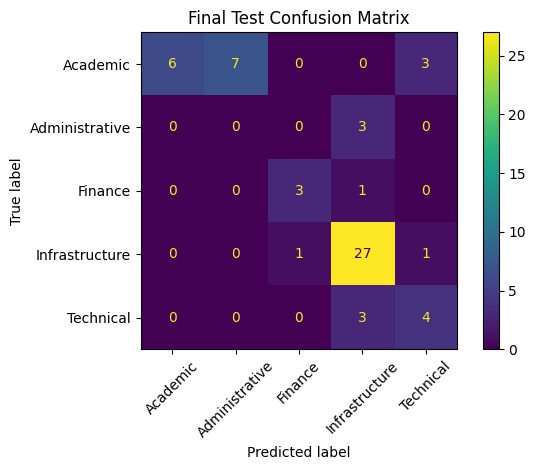

In [59]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = final_model.classes_

cm = confusion_matrix(
    y_test_final,
    final_pred,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(xticks_rotation=45)
plt.title("Final Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [60]:

errors = pd.DataFrame({
    "complaint": test_df["Complaint_Description"].reset_index(drop=True),
    "actual": y_test_final.reset_index(drop=True),
    "predicted": final_pred
})

errors = errors[errors["actual"] != errors["predicted"]]

print("Total incorrect predictions:", len(errors))
display(errors.reset_index(drop=True))


Total incorrect predictions: 19


,complaint,actual,predicted
0,some computers in LAB is very very laggy (7B01...,Technical,Infrastructure
1,The maximum obtainable grade point for the Imp...,Academic,Administrative
2,Each floor should have one wheelchair available.,Administrative,Infrastructure
3,Teacher's evaluation must be taken when semest...,Academic,Administrative
4,The quiz questions often do not align with the...,Academic,Technical
5,some computers in LAB is very very laggy (7B01...,Technical,Infrastructure
6,The maximum obtainable grade point for the Imp...,Academic,Administrative
7,Each floor should have one wheelchair accessible.,Administrative,Infrastructure
8,The projector screen is not visible from the b...,Infrastructure,Technical
9,Teacher's evaluation must be taken when semest...,Academic,Administrative


In [61]:

print("Error rows:", len(errors))
print(
    "Unique complaint texts:",
    errors["complaint"].nunique()
)

print("\nRepeated complaint texts:")
print(
    errors["complaint"].value_counts()
    .loc[lambda counts: counts > 1]
)


Error rows: 19
Unique complaint texts: 19

Repeated complaint texts:
Series([], Name: count, dtype: int64)


In [62]:

print("Errors by actual category:")
print(errors["actual"].value_counts())

print("\nActual vs predicted error counts:")
print(pd.crosstab(
    errors["actual"],
    errors["predicted"],
    rownames=["Actual"],
    colnames=["Predicted"]
))


Errors by actual category:
actual
Academic          10
Technical          3
Administrative     3
Infrastructure     2
Finance            1
Name: count, dtype: int64

Actual vs predicted error counts:
Predicted       Administrative  Finance  Infrastructure  Technical
Actual                                                            
Academic                     7        0               0          3
Administrative               0        0               3          0
Finance                      0        0               1          0
Infrastructure               0        1               0          1
Technical                    0        0               3          0


## Day 11: Category-wise Evaluation and Error Analysis

### Objective
Evaluate final test performance and investigate incorrect predictions using a confusion matrix and complaint-level error analysis.

### Overall Test Results
- Test samples: 59
- Correct predictions: 40
- Incorrect predictions: 19
- Accuracy: 67.80%
- Macro F1-score: 0.54
- Weighted F1-score: 0.68

### Category-wise Findings
- Infrastructure achieved the strongest F1-score of 0.86, with 27 of 29 complaints correctly classified.
- Academic achieved an F1-score of 0.55, with 10 incorrect predictions.
- Technical achieved an F1-score of 0.53, with three incorrect predictions.
- Administrative achieved an F1-score of 0.00; all three test examples were misclassified.
- Finance achieved an F1-score of 0.75, based on only four test examples.

### Error Analysis
The 19 incorrect predictions contained 19 unique complaint texts.

The error distribution by actual category was:
- Academic: 10 errors
- Administrative: 3 errors
- Technical: 3 errors
- Infrastructure: 2 errors
- Finance: 1 error

Academic complaints were most frequently predicted as Administrative (7 cases) or Technical (3 cases). All three Administrative errors and all three Technical errors were predicted as Infrastructure.

### Interpretation and Limitations
The error patterns suggest possible confusion between related complaint categories. These observations do not establish the underlying causes; category definitions and training examples need further review.

The test set is small, particularly for Administrative and Finance. These results should be interpreted cautiously. The held-out test set is retained for evaluation rather than repeated model tuning.

### Conclusion
The analysis identified Academic classification and the distinction between Administrative, Technical, and Infrastructure complaints as key areas for further investigation. Future experiments should use training and validation data and should be evaluated without tuning against the final test set.

In [63]:

for category in sorted(train_df["Category"].unique()):
    print("\n" + "=" * 60)
    print("CATEGORY:", category)
    print("=" * 60)

    examples = train_df.loc[
        train_df["Category"] == category,
        "Complaint_Description"
    ].head(5)

    for i, complaint in enumerate(examples, start=1):
        print(f"{i}. {complaint}")



CATEGORY: Academic
1. We can never find our adviser
2. CSE Dept doesnt have qualified teachers
3. We need more research facilities in our university and also we need more experienced professors
4. CSE Dept doesnt have qualified teachers
5. We need more research facilities in our university and also we need more experienced professors

CATEGORY: Administrative
1. Due to continuous loud talking by some students in the library, it has become very difficult to study and maintain concentration
2. Library and study room spaces are insufficient and remain overcrowded during peak hours.
3. Just like there is a space for prayer in front of the Mechanical Department, a similar space should be provided in front of almost every department for prayers.
4. Pressure is applied to participate in co-curricular activities by seniors, even if students are unwilling or facing problems.
5. The size for the teacup in the cafeteria should be larger.

CATEGORY: Finance
1. A studentship certificate costs a st

In [64]:

print("Total training rows:", len(train_df))

print(
    "Exact duplicate complaint texts:",
    train_df["Complaint_Description"].duplicated().sum()
)

print(
    "Unique complaint texts:",
    train_df["Complaint_Description"].nunique()
)


Total training rows: 273
Exact duplicate complaint texts: 5
Unique complaint texts: 268


In [65]:

dup_rows = train_df[
    train_df["Complaint_Description"].duplicated(keep=False)
].sort_values("Complaint_Description")

print(
    dup_rows[["Complaint_Description", "Category"]]
    .to_string(index=False)
)


                                                                                                       Complaint_Description Category
                                                                                     CSE Dept doesnt have qualified teachers Academic
                                                                                     CSE Dept doesnt have qualified teachers Academic
                                                                                    CSE Dept doesnt have qualified teachers. Academic
                                                                                    CSE Dept doesnt have qualified teachers. Academic
                                                               CSE Dept doesnt have qualified teachers. Please look into it. Academic
                                                               CSE Dept doesnt have qualified teachers. Please look into it. Academic
                             We need more research facilities 

In [66]:

train_texts = set(
    train_df["Complaint_Description"].str.lower().str.strip()
)

test_texts = set(
    test_df["Complaint_Description"].str.lower().str.strip()
)

overlap = train_texts.intersection(test_texts)

print("Unique train complaint texts:", len(train_texts))
print("Unique test complaint texts:", len(test_texts))
print("Exact normalized overlap:", len(overlap))

for text in list(overlap)[:10]:
    print("-", text)


Unique train complaint texts: 268
Unique test complaint texts: 59
Exact normalized overlap: 0


In [67]:

train_dedup = train_df.drop_duplicates(
    subset="Complaint_Description"
).copy()

print("Original training rows:", len(train_df))
print("After deduplication:", len(train_dedup))
print(
    "Rows removed:",
    len(train_df) - len(train_dedup)
)


Original training rows: 273
After deduplication: 268
Rows removed: 5


In [68]:

# Create a validation split from deduplicated data
from sklearn.model_selection import train_test_split

dedup_tr, dedup_val = train_test_split(
    train_dedup,
    test_size=0.2,
    random_state=42,
    stratify=train_dedup["Category"]
)

print("Deduplicated training split:", len(dedup_tr))
print("Deduplicated validation split:", len(dedup_val))

print("\nTraining category counts:")
print(dedup_tr["Category"].value_counts())

print("\nValidation category counts:")
print(dedup_val["Category"].value_counts())


Deduplicated training split: 214
Deduplicated validation split: 54

Training category counts:
Category
Infrastructure    91
Technical         46
Academic          35
Finance           23
Administrative    19
Name: count, dtype: int64

Validation category counts:
Category
Infrastructure    23
Technical         12
Academic           8
Finance            6
Administrative     5
Name: count, dtype: int64


In [69]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Original training data
orig_tfidf = TfidfVectorizer(max_features=1000, ngram_range=(1, 2))
orig_x = orig_tfidf.fit_transform(x_tr)
orig_val_x = orig_tfidf.transform(x_val)

orig_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)
orig_model.fit(orig_x, y_tr)
orig_pred = orig_model.predict(orig_val_x)

# Deduplicated training data, same validation examples
dedup_tfidf = TfidfVectorizer(max_features=1000, ngram_range=(1, 2))
dedup_x = dedup_tfidf.fit_transform(dedup_tr["clean_text"])
dedup_val_x = dedup_tfidf.transform(x_val)

dedup_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)
dedup_model.fit(dedup_x, dedup_tr["Category"])
dedup_pred = dedup_model.predict(dedup_val_x)

print("Original accuracy:", round(accuracy_score(y_val, orig_pred), 4))
print("Original macro F1:", round(f1_score(y_val, orig_pred, average="macro"), 4))

print("Deduplicated accuracy:", round(accuracy_score(y_val, dedup_pred), 4))
print("Deduplicated macro F1:", round(f1_score(y_val, dedup_pred, average="macro"), 4))


Original accuracy: 0.9636
Original macro F1: 0.9607
Deduplicated accuracy: 0.9636
Deduplicated macro F1: 0.9746


In [70]:

from sklearn.metrics import classification_report

print("ORIGINAL MODEL")
print(classification_report(
    y_val, orig_pred, zero_division=0
))

print("\nDEDUPLICATED MODEL")
print(classification_report(
    y_val, dedup_pred, zero_division=0
))



ORIGINAL MODEL
                precision    recall  f1-score   support

      Academic       1.00      1.00      1.00         9
Administrative       1.00      0.80      0.89         5
       Finance       1.00      1.00      1.00         6
Infrastructure       0.92      1.00      0.96        23
     Technical       1.00      0.92      0.96        12

      accuracy                           0.96        55
     macro avg       0.98      0.94      0.96        55
  weighted avg       0.97      0.96      0.96        55


DEDUPLICATED MODEL
                precision    recall  f1-score   support

      Academic       1.00      1.00      1.00         9
Administrative       1.00      1.00      1.00         5
       Finance       1.00      1.00      1.00         6
Infrastructure       0.96      0.96      0.96        23
     Technical       0.92      0.92      0.92        12

      accuracy                           0.96        55
     macro avg       0.97      0.97      0.97        55
  weight

## Day 12: Dataset Quality Audit and Duplicate Handling

### Objective
Inspect complaint categories, identify repeated complaint texts, check for exact text overlap between training and test datasets, and evaluate whether removing exact duplicates affects model performance.

### 1. Category Sample Review
Reviewed sample complaints from all five categories:

- **Academic:** Adviser availability, teacher qualifications, and research facilities.
- **Administrative:** Library conditions, study spaces, prayer facilities, student activities, and cafeteria services.
- **Finance:** Student fees, certificates, and payment services.
- **Infrastructure:** Drinking water, washrooms, lifts, prayer rooms, and physical facilities.
- **Technical:** Wi-Fi availability, bus tracking systems, and projector functionality.

Some complaint types, such as projector problems, may overlap between categories depending on the dataset's labeling rules.

### 2. Duplicate Text Audit
- Original training rows: 273
- Unique training complaint texts: 268
- Exact duplicate occurrences beyond the first instance: 5
- The inspected repeated texts belonged to the Academic category.
- Some complaints had similar meanings but differed in punctuation or wording.

The original training data was preserved. Duplicate rows were not automatically removed from the main dataset.

### 3. Train–Test Text Overlap Check
Complaint texts were converted to lowercase and leading/trailing whitespace was removed before comparison.

- Unique training texts: 268
- Unique test texts: 59
- Exact normalized text overlap: 0

This check found no exact normalized text matches between the training and test sets. It does not rule out all near-duplicate or semantically similar complaints.

### 4. Duplicate Removal Experiment
Two class-balanced Logistic Regression models were compared using TF-IDF features with unigrams and bigrams.

**Original training data**
- Training rows before the validation split: 273
- Accuracy on the 55-example validation set: 96.36%
- Macro F1-score: 0.9607

**Deduplicated training data**
- Training rows after removing exact duplicate complaint texts: 268
- Accuracy on the same 55-example validation set: 96.36%
- Macro F1-score: 0.9746

### 5. Category-wise Comparison

| Category | Original F1 | Deduplicated F1 |
|---|---:|---:|
| Academic | 1.00 | 1.00 |
| Administrative | 0.89 | 1.00 |
| Finance | 1.00 | 1.00 |
| Infrastructure | 0.96 | 0.96 |
| Technical | 0.96 | 0.92 |

The deduplicated model improved the Administrative F1-score but had a lower Technical F1-score. Accuracy remained unchanged.

### 6. Interpretation
Removing exact duplicate texts produced a small increase in validation macro F1-score without changing validation accuracy. However, the improvement was not consistent across all categories.

The results suggest that duplicate handling may affect category-wise performance, but a single validation split is not enough to establish that deduplication consistently improves generalization.

### 7. Limitations
- The dataset is small, with only 273 training rows and 59 test rows.
- Some categories may contain conceptually overlapping complaints.
- Exact duplicate checks do not detect all near-duplicates.
- The validation set is small, so metrics may vary with different splits.
- The final held-out test set must remain separate from model selection and tuning.

### Conclusion
The dataset audit identified five duplicate occurrences in the training data and no exact normalized text overlap between training and test complaint texts. In the duplicate-removal experiment, accuracy remained

In [71]:

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42
)

svm_model.fit(x_tr_ng, y_tr)

svm_pred = svm_model.predict(x_val_ng)

print(
    "SVM accuracy:",
    round(accuracy_score(y_val, svm_pred), 4)
)

print(
    "SVM macro F1:",
    round(f1_score(y_val, svm_pred, average="macro"), 4)
)


SVM accuracy: 0.9455
SVM macro F1: 0.9474


In [72]:

from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    svm_pred,
    zero_division=0
))



                precision    recall  f1-score   support

      Academic       1.00      1.00      1.00         9
Administrative       1.00      0.80      0.89         5
       Finance       1.00      1.00      1.00         6
Infrastructure       0.88      1.00      0.94        23
     Technical       1.00      0.83      0.91        12

      accuracy                           0.95        55
     macro avg       0.98      0.93      0.95        55
  weighted avg       0.95      0.95      0.94        55



In [74]:

hinglish_complaints = [
    "College ka WiFi kaam nahi kar raha hai.",
    "Meri fees payment update nahi hui hai.",
    "Professor ne abhi tak assignment ke marks upload nahi kiye.",
    "Classroom ka projector kharab hai.",
    "Mujhe abhi tak student ID card nahi mila.",
    "Library mein paani peene ki machine kaam nahi kar rahi.",
    "Exam ka result portal par show nahi ho raha.",
    "College office meri scholarship application ka jawab nahi de raha."
]

expected = [
    "Technical",
    "Finance",
    "Academic",
    "Infrastructure",
    "Administrative",
    "Infrastructure",
    "Academic",
    "Administrative"
]

hinglish_vec = final_tfidf.transform(hinglish_complaints)
hinglish_pred = final_model.predict(hinglish_vec)

hinglish_results = pd.DataFrame({
    "complaint": hinglish_complaints,
    "expected": expected,
    "predicted": hinglish_pred
})

hinglish_results["match"] = (
    hinglish_results["expected"] == hinglish_results["predicted"]
)

display(hinglish_results)
print("Exploratory accuracy:", round(hinglish_results["match"].mean() * 100, 2), "%")


,complaint,expected,predicted,match
0,College ka WiFi kaam nahi kar raha hai.,Technical,Technical,True
1,Meri fees payment update nahi hui hai.,Finance,Finance,True
2,Professor ne abhi tak assignment ke marks uplo...,Academic,Infrastructure,False
3,Classroom ka projector kharab hai.,Infrastructure,Infrastructure,True
4,Mujhe abhi tak student ID card nahi mila.,Administrative,Finance,False
5,Library mein paani peene ki machine kaam nahi ...,Infrastructure,Infrastructure,True
6,Exam ka result portal par show nahi ho raha.,Academic,Finance,False
7,College office meri scholarship application ka...,Administrative,Infrastructure,False


Exploratory accuracy: 50.0 %


## Day 13: Model Comparison and Hinglish Complaint Evaluation

### Objective
Compare Logistic Regression with Linear SVM and explore how the English-trained model handles Hindi/Hinglish complaints.

### 1. Model Comparison
Both models used TF-IDF unigram and bigram features with class-balanced training.

| Metric | Logistic Regression | Linear SVM |
|---|---:|---:|
| Validation accuracy | 96.36% | 94.55% |
| Validation macro F1 | 0.9607 | 0.9474 |

Logistic Regression performed better overall on the current validation split and remains the preferred candidate based on these results.

### 2. Hinglish Evaluation
Eight manually labeled Hinglish complaints were tested using the final trained Logistic Regression model.

- Correct predictions: 4 out of 8
- Exploratory accuracy: 50%

Correctly classified examples included a Wi-Fi complaint, a fee-payment complaint, a projector complaint, and a drinking-water machine complaint.

Incorrect examples included complaints about assignment marks, student ID cards, exam results, and scholarship applications.

### 3. Interpretation
The experiment suggests that the English-trained model may struggle with some Hinglish complaints, particularly where category-specific wording differs from the training examples. However, this small test does not establish the exact cause of errors or provide a reliable estimate of general Hindi/Hinglish performance.

### 4. Limitations
- Only eight Hinglish complaints were tested.
- Expected labels were assigned manually and may depend on category definitions.
- The original training dataset contains English complaints, so multilingual support has not been established.
- Validation performance is higher than the previously measured final test accuracy of 67.80%; these metrics represent different evaluations.

### Conclusion
Logistic Regression outperformed Linear SVM on the current validation split. The exploratory Hinglish test achieved 50% accuracy, indicating that further multilingual data collection and evaluation are needed before claiming reliable Hindi/Hinglish support.

In [75]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import joblib
import os

final_tfidf = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2)
)

x_final = final_tfidf.fit_transform(
    train_dedup["clean_text"]
)

final_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

final_model.fit(
    x_final,
    train_dedup["Category"]
)

print("Final model trained.")
print("Training rows:", len(train_dedup))
print("TF-IDF feature count:", x_final.shape[1])


Final model trained.
Training rows: 268
TF-IDF feature count: 1000


In [76]:

import os
import joblib

save_dir = "/content/drive/MyDrive/college_complaint_models"
os.makedirs(save_dir, exist_ok=True)

joblib.dump(
    final_model,
    os.path.join(save_dir, "complaint_model.joblib")
)

joblib.dump(
    final_tfidf,
    os.path.join(save_dir, "tfidf_vectorizer.joblib")
)

print("Final model and vectorizer saved.")


Final model and vectorizer saved.


In [77]:

loaded_model = joblib.load(
    os.path.join(save_dir, "complaint_model.joblib")
)

loaded_tfidf = joblib.load(
    os.path.join(save_dir, "tfidf_vectorizer.joblib")
)

test_complaint = [
    "My tuition fee payment has not been updated."
]

test_vec = loaded_tfidf.transform(test_complaint)
loaded_pred = loaded_model.predict(test_vec)

print("Prediction:", loaded_pred[0])
print(
    "Matches current model:",
    loaded_pred[0] == final_model.predict(
        final_tfidf.transform(test_complaint)
    )[0]
)


Prediction: Finance
Matches current model: True


In [78]:
from sklearn.metrics import accuracy_score, classification_report, f1_score

x_test_final = final_tfidf.transform(
    test_df["Complaint_Description"].str.lower()
)

y_test_final = test_df["Category"]
final_pred = final_model.predict(x_test_final)

print("Test Accuracy:", round(accuracy_score(y_test_final, final_pred), 4))
print("Macro F1:", round(f1_score(y_test_final, final_pred, average="macro", zero_division=0), 4))
print("\nClassification Report:\n")
print(classification_report(y_test_final, final_pred, zero_division=0))

Test Accuracy: 0.6949
Macro F1: 0.5871

Classification Report:

                precision    recall  f1-score   support

      Academic       1.00      0.38      0.55        16
Administrative       0.30      1.00      0.46         3
       Finance       0.75      0.75      0.75         4
Infrastructure       0.82      0.93      0.87        29
     Technical       0.33      0.29      0.31         7

      accuracy                           0.69        59
     macro avg       0.64      0.67      0.59        59
  weighted avg       0.78      0.69      0.69        59



In [81]:
import joblib
import os

save_dir = "/content/drive/MyDrive/college_complaint_models"

model = joblib.load(
    os.path.join(save_dir, "complaint_model.joblib")
)
vectorizer = joblib.load(
    os.path.join(save_dir, "tfidf_vectorizer.joblib")
)

complaint = input("Enter your college complaint: ")

complaint_vector = vectorizer.transform([complaint])
prediction = model.predict(complaint_vector)[0]

print("\nPredicted Complaint Category:", prediction)

Enter your college complaint: The WiFi in my college library is not working.

Predicted Complaint Category: Technical
